**[Course Home](../README.md) | [Conceptual Track](../conceptual/00_START_HERE.ipynb) | [Next: Ch 01: Quantifying Surprise](01_self_information_and_shannon_entropy.ipynb)**

*Part I: Foundations of Uncertainty & Optimal Description — Chapter 00 of 11*

---

# Chapter 0: The Big Picture — Python Laboratory
### *Simulating the 20 Questions Game, Empirical Entropy, and Verifying Environment Capabilities*

Welcome to the Python Laboratory for Chapter 0! In this introductory workbook, we will verify our local scientific Python environment and simulate the physical mental model behind Shannon Information Theory: **The Game of 20 Questions**.

---

### Table of Contents
1. **Part 1: Environment Verification & Scientific Dependencies**
2. **Part 2: The 20 Questions Simulation (Uniform vs. Skewed Distributions)**
3. **Part 3: The Empirical Additivity of Information**
4. **Part 4: Multi-Panel Visualization of Ignorance Profiles**
5. **Part 5: Hands-On 3-Tier Scaffolding Challenges**


## Part 1: Environment Verification & Scientific Dependencies

We verify our Python computational stack (`numpy`, `scipy`, `matplotlib`, and `pandas`).

In [1]:
import sys
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd

print(f"Python Version: {sys.version.split()[0]}")
print(f"NumPy Version:  {np.__version__}")
print(f"SciPy Version:  {stats.__file__}")
print("Dependencies verified successfully!")


Python Version: 3.12.10
NumPy Version:  2.5.2
SciPy Version:  C:\Users\tarob\.jupyter_env\Lib\site-packages\scipy\stats\__init__.py
Dependencies verified successfully!


## Part 2: The 20 Questions Simulation

We simulate the expected questions needed to identify a state drawn from two different distributions:
1. **Uniform World**: 8 states with equal probability $p = 1/8 = 0.125$.
2. **Skewed World**: 8 states where Key 0 occurs $80\%$ of the time, and Keys 1 through 7 share the remainder.


In [2]:
def simulate_20_questions(probs, n_trials=10000, seed=42):
    np.random.seed(seed)
    probs = np.asarray(probs, dtype=float)
    probs /= np.sum(probs)
    
    # Theoretical Shannon Entropy: H(X) = - sum(p * log2(p))
    theoretical_entropy = -np.sum(probs * np.log2(probs + 1e-15))
    
    # Draw actual random outcomes
    samples = np.random.choice(len(probs), size=n_trials, p=probs)
    
    # Optimal question cost is roughly -log2(p) (idealized binary prefix length)
    ideal_questions = -np.log2(probs[samples] + 1e-15)
    empirical_mean = np.mean(ideal_questions)
    empirical_std = np.std(ideal_questions)
    
    return theoretical_entropy, empirical_mean, empirical_std

# Define scenarios
p_uniform = np.ones(8) / 8.0
p_skewed = np.array([0.80, 0.05, 0.03, 0.03, 0.03, 0.02, 0.02, 0.02])

h_uni, emp_uni, std_uni = simulate_20_questions(p_uniform)
h_skew, emp_skew, std_skew = simulate_20_questions(p_skewed)

print("="*60)
print(f"UNIFORM WORLD:  Theoretical H = {h_uni:.4f} bits | Empirical Questions = {emp_uni:.4f} ± {std_uni:.4f}")
print(f"SKEWED WORLD:   Theoretical H = {h_skew:.4f} bits | Empirical Questions = {emp_skew:.4f} ± {std_skew:.4f}")
print("="*60)


UNIFORM WORLD:  Theoretical H = 3.0000 bits | Empirical Questions = 3.0000 ± 0.0000
SKEWED WORLD:   Theoretical H = 1.2676 bits | Empirical Questions = 1.2479 ± 1.8870


## Part 3: The Additivity Property of Information

Here we verify computationally that for independent random variables $X$ and $Y$:
$$H(X, Y) = H(X) + H(Y)$$
When variables are independent, joint surprise is exactly the sum of marginal surprises!


In [3]:
# Coin Toss (p_heads = 0.5) and 4-sided Die (uniform 0.25)
px = np.array([0.5, 0.5])
py = np.array([0.25, 0.25, 0.25, 0.25])

hx = -np.sum(px * np.log2(px))
hy = -np.sum(py * np.log2(py))

# Joint Distribution P(X, Y) = P(X) * P(Y)
pxy = np.outer(px, py)
h_joint = -np.sum(pxy * np.log2(pxy))

print(f"H(Coin)       = {hx:.3f} bits")
print(f"H(4-Die)      = {hy:.3f} bits")
print(f"H(Coin + Die) = {h_joint:.3f} bits")
print(f"Additivity Check: H(X) + H(Y) = {hx + hy:.3f} == H(X,Y) = {h_joint:.3f} -> {np.isclose(hx + hy, h_joint)}")


H(Coin)       = 1.000 bits
H(4-Die)      = 2.000 bits
H(Coin + Die) = 3.000 bits
Additivity Check: H(X) + H(Y) = 3.000 == H(X,Y) = 3.000 -> True


## Part 4: Multi-Panel Visualization of Ignorance Profiles

Let's visualize the contrast between high-entropy and low-entropy systems side-by-side.


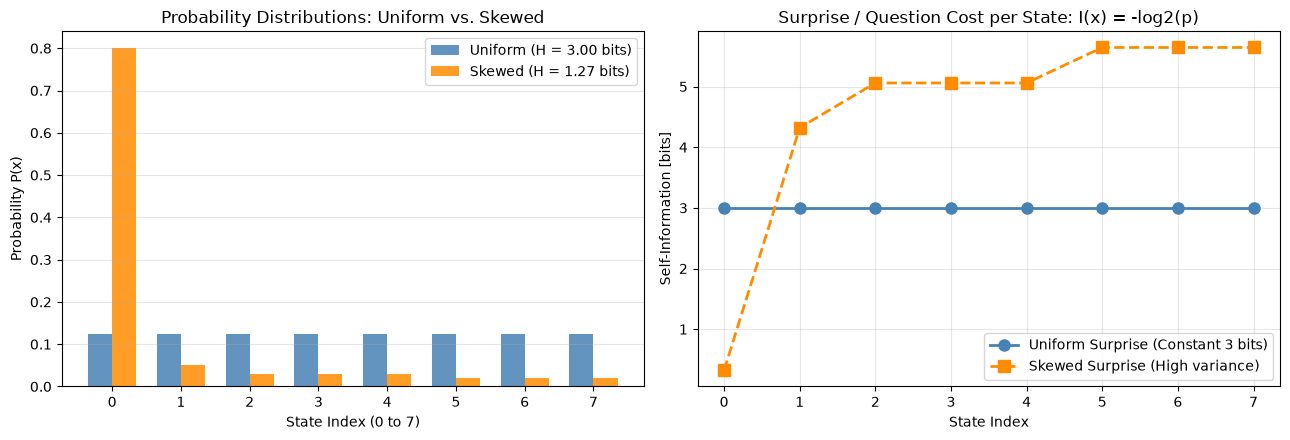

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Bar charts of probabilities
indices = np.arange(8)
width = 0.35
ax1.bar(indices - width/2, p_uniform, width=width, label=f"Uniform (H = {h_uni:.2f} bits)", color="steelblue", alpha=0.85)
ax1.bar(indices + width/2, p_skewed, width=width, label=f"Skewed (H = {h_skew:.2f} bits)", color="darkorange", alpha=0.85)
ax1.set_title("Probability Distributions: Uniform vs. Skewed", fontsize=12)
ax1.set_xlabel("State Index (0 to 7)")
ax1.set_ylabel("Probability P(x)")
ax1.set_xticks(indices)
ax1.grid(True, alpha=0.3, axis="y")
ax1.legend()

# 2. Point Surprise Curves: -log2(p)
surprise_uni = -np.log2(p_uniform)
surprise_skew = -np.log2(p_skewed)
ax2.plot(indices, surprise_uni, 'o-', color="steelblue", lw=2, markersize=8, label="Uniform Surprise (Constant 3 bits)")
ax2.plot(indices, surprise_skew, 's--', color="darkorange", lw=2, markersize=8, label="Skewed Surprise (High variance)")
ax2.set_title("Surprise / Question Cost per State: I(x) = -log2(p)", fontsize=12)
ax2.set_xlabel("State Index")
ax2.set_ylabel("Self-Information [bits]")
ax2.set_xticks(indices)
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


## Part 5: Hands-On 3-Tier Scaffolding Challenges

### 🟢 Warmup (Tier 1): The Fair 16-Sided Die
Calculate the theoretical Shannon entropy in bits for a fair 16-sided die ($p_i = 1/16$). How many yes/no questions do you need on average?


In [5]:
# Tier 1 Solution Space
p_16 = np.ones(16) / 16.0
# Your calculation here:
h_16 = -np.sum(p_16 * np.log2(p_16))
print(f"Tier 1 Answer: H(16-sided die) = {h_16:.2f} bits.")


Tier 1 Answer: H(16-sided die) = 4.00 bits.


### 🟡 Diagnostic (Tier 2): Zipf\'s Law in Production
Natural language and web traffic frequently follow **Zipf\'s law**: $P(k) \propto 1/k^s$ for rank $k = 1, \dots, N$.
Compute the Shannon entropy and Perplexity for a Zipfian vocabulary of $N = 100$ items with $s = 1.0$. Compare it to the uniform distribution over 100 items.


In [6]:
# Tier 2 Solution Space
ranks = np.arange(1, 101)
zipf_probs = 1.0 / ranks
zipf_probs /= np.sum(zipf_probs)

h_zipf = -np.sum(zipf_probs * np.log2(zipf_probs))
perp_zipf = 2.0 ** h_zipf

h_uni100 = np.log2(100)
perp_uni100 = 100.0

print(f"Zipf(100):    H = {h_zipf:.2f} bits | Perplexity = {perp_zipf:.2f} (behaves like an ~{int(perp_zipf)}-sided die)")
print(f"Uniform(100): H = {h_uni100:.2f} bits | Perplexity = {perp_uni100:.2f} (behaves like a 100-sided die)")


Zipf(100):    H = 5.31 bits | Perplexity = 39.68 (behaves like an ~39-sided die)
Uniform(100): H = 6.64 bits | Perplexity = 100.00 (behaves like a 100-sided die)


### 🔴 Capstone Challenge (Tier 3): The Optimal First Question
Suppose you have a 4-state system with probabilities:
$$P = [0.45, 0.35, 0.15, 0.05]$$
Write a Python script that tests all possible binary splits (e.g., State 0 vs {1,2,3}, or {0,1} vs {2,3}) and determines which question maximizes Expected Information Gain.


In [7]:
# Tier 3 Solution Space
p = np.array([0.45, 0.35, 0.15, 0.05])
h_prior = -np.sum(p * np.log2(p))

# Candidate Split: Is it in {0}? (prob = 0.45)
# Candidate Split: Is it in {0, 1}? (prob = 0.45 + 0.35 = 0.80)
# Candidate Split: Is it in {0, 2}? (prob = 0.45 + 0.15 = 0.60)
candidates = [
    ([0], [1, 2, 3]),
    ([0, 1], [2, 3]),
    ([0, 2], [1, 3]),
    ([0, 3], [1, 2])
]

print(f"Prior Entropy H(X): {h_prior:.3f} bits\n")
for group_yes, group_no in candidates:
    p_yes = np.sum(p[group_yes])
    p_no = 1.0 - p_yes
    
    # Conditional entropy H(X | Question)
    p_cond_yes = p[group_yes] / p_yes
    p_cond_no = p[group_no] / p_no
    
    h_yes = -np.sum(p_cond_yes * np.log2(p_cond_yes + 1e-15))
    h_no = -np.sum(p_cond_no * np.log2(p_cond_no + 1e-15))
    
    h_cond = p_yes * h_yes + p_no * h_no
    info_gain = h_prior - h_cond
    print(f"Split {group_yes} vs {group_no}: P(Yes)={p_yes:.2f} | Remaining H={h_cond:.3f} | Info Gain={info_gain:.3f} bits")


Prior Entropy H(X): 1.675 bits

Split [0] vs [1, 2, 3]: P(Yes)=0.45 | Remaining H=0.682 | Info Gain=0.993 bits
Split [0, 1] vs [2, 3]: P(Yes)=0.80 | Remaining H=0.953 | Info Gain=0.722 bits
Split [0, 2] vs [1, 3]: P(Yes)=0.60 | Remaining H=0.704 | Info Gain=0.971 bits
Split [0, 3] vs [1, 2]: P(Yes)=0.50 | Remaining H=0.675 | Info Gain=1.000 bits


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/00_START_HERE.ipynb) | [Next: Ch 01: Quantifying Surprise](01_self_information_and_shannon_entropy.ipynb)**
